# Week 9 - Multivariate Analysis, part 2

# 1. Lesson - no lesson this week

# 2. Weekly graph question

The graph below plots the first two principal component scores in a scatter plot.  What can be said about the three outliers in the upper left corner of the graph?  Is their first principal component score high or low?  What about their second principal component score?  What does that mean about their values in series_1, series_2, and series_3?  It seems to me that you can say something about series_3 (what can you say?) but you may have a harder time saying something about series_1 and series_2, and an almost impossible time saying anything about the relative values of series_1 and series_2.  Why is that?  How are series_1 and series_2 related, according to how they were created?  If you like, try drawing a pairplot for all three series and see what you get.

Overall, what are the advantages and disadvantages of the graph below?  Does it show anything interesting?

[0.79916477 0.18990532 0.01092991]
[[ 0.26541493  0.30096233  0.91595665]
 [ 0.60337553  0.6891417  -0.40127506]
 [ 0.75199261 -0.65917023 -0.00131519]]


Text(0, 0.5, 'Second Principal Component Score')

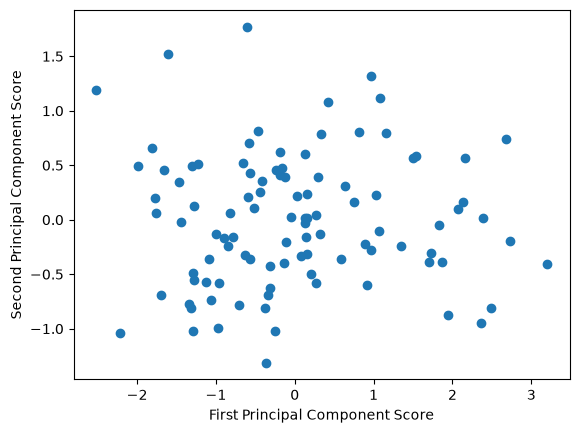

In [1]:
import numpy as np
import pandas as pd
from sklearn import decomposition
import matplotlib.pyplot as plt

np.random.seed(0)
num_points = 100
series_1 = np.random.normal(loc = 2, scale = 0.5, size = num_points)
series_2 = series_1 * (1 + np.random.normal(loc = 0, scale = 0.1, size = num_points))
series_3 = series_1 * (1 + np.random.normal(loc = 0, scale = 0.5, size = num_points))
df = pd.DataFrame({'ser1': series_1, 'ser2': series_2, 'ser3': series_3})
df = df - df.mean() # set mean to zero, so we don't have to subtract mean from the principal component scores

pca3 = decomposition.PCA(n_components = 3)
pca3.fit(df)
print(pca3.explained_variance_ratio_)
print(pca3.components_)

first_principal_component_score = df.dot(pca3.components_[0])
second_principal_component_score = df.dot(pca3.components_[1])
plt.scatter(first_principal_component_score, second_principal_component_score)
plt.xlabel("First Principal Component Score")
plt.ylabel("Second Principal Component Score")

The three outliers in the upper-left have low first principal component scores and high second principal component scores. Since the first principal component places the greatest weight on series_3, the low first component scores suggest that these observations have relatively low values of series_3. The second principal component gives positive weights to series_1 and series_2 and a negative weight to series_3, so the high second component scores suggest that series_1 and series_2 are relatively high compared with series_3.

It is difficult to say much about the difference between series_1 and series_2 because they were created to be very strongly related. Series_2 was generated from series_1 with only a small amount of random noise, so they usually move together.

The advantage of the PCA scatter plot is that it reduces three variables to two dimensions while still showing most of the variation in the data. The first two components together explain about 99% of the variance. The disadvantage is that the axes are combinations of the original variables, so they are harder to interpret directly. The graph is still useful because it makes the three unusual observations easy to identify.

# 3. Working on your chosen project datasets this semester

This week, you will do the same types of exercises as last week, but you should use your chosen datasets that someone in your class found last semester. (They likely will not be the particular datasets that you found yourself.)

Here are some types of analysis you can do:
Draw heatmaps.

Draw bubble plots.

Perform Principal Component Analysis to find out the directions in which the data varies.  Can you represent the data using only its projection onto its first principal component, using the methods described in Week 8?  How much of the variance would this capture?

Try performing linear regression analysis using different sets of features.  Which features seem most likely to be useful to predict other features?

Conclusions:
Explain what conclusions you would draw from this analysis: are the data what you expect? Are the data likely to be usable? If the data are not useable, find some new data!

Do you see any outliers? (Data points that are far from the rest of the data).

Does the Principal Component Analysis suggest a way to represent the data using fewer dimensions than usual - using its first one or two principal component scores, perhaps?

Try using your correlation information from previous weeks to help choose features for linear regression.

In [2]:
# Load the diabetes dataset
df = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")

# Look at the first few rows
df.head()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [3]:
# Select variables that were important in our earlier diabetes analysis
selected_vars = [
    "Diabetes_012",
    "BMI",
    "HighBP",
    "HighChol",
    "GenHlth",
    "PhysHlth",
    "Age",
    "Income"
]

# Create a smaller dataframe containing only these variables
df_selected = df[selected_vars]

# Calculate the correlations
correlation_matrix = df_selected.corr()

correlation_matrix

,Diabetes_012,BMI,HighBP,HighChol,GenHlth,PhysHlth,Age,Income
Diabetes_012,1.000000,0.224379,0.271596,0.209085,0.302587,0.176287,0.185026,-0.171483
BMI,0.224379,1.000000,0.213748,0.106722,0.239185,0.121141,-0.036618,-0.100069
HighBP,0.271596,0.213748,1.000000,0.298199,0.300530,0.161212,0.344452,-0.171235
HighChol,0.209085,0.106722,0.298199,1.000000,0.208426,0.121751,0.272318,-0.085459
GenHlth,0.302587,0.239185,0.300530,0.208426,1.000000,0.524364,0.152450,-0.370014
PhysHlth,0.176287,0.121141,0.161212,0.121751,0.524364,1.000000,0.099130,-0.266799
Age,0.185026,-0.036618,0.344452,0.272318,0.152450,0.099130,1.000000,-0.127775
Income,-0.171483,-0.100069,-0.171235,-0.085459,-0.370014,-0.266799,-0.127775,1.000000


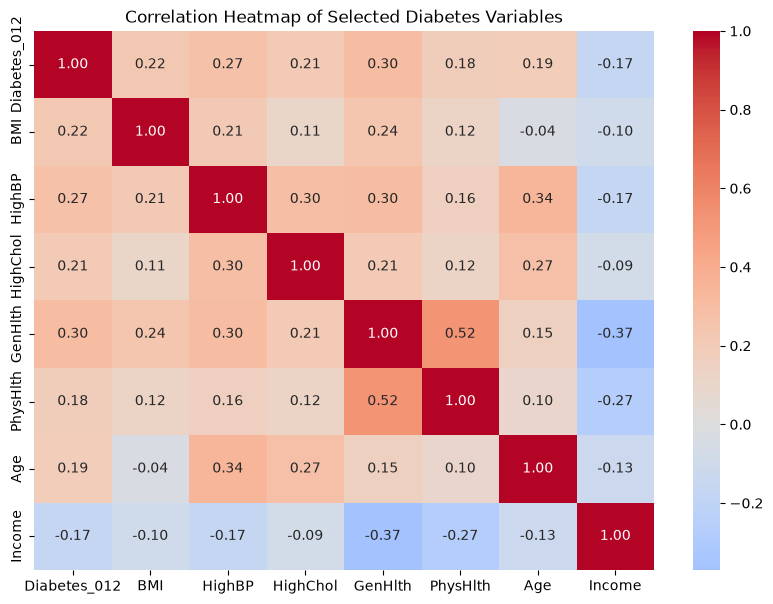

In [4]:
# Create a correlation heatmap
import seaborn as sns
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Selected Diabetes Variables")

plt.show()

The heatmap shows several meaningful relationships among the diabetes-related variables. The strongest positive correlation is between general health and physical health at about 0.52, suggesting that poorer general health is associated with more physically unhealthy days. High blood pressure also shows moderate positive relationships with age, general health, and high cholesterol. Diabetes status is most strongly related to general health, high blood pressure, and BMI. Income shows negative relationships with general health and physical health, suggesting that participants in higher income categories tend to report better health. Overall, the heatmap shows that diabetes status is associated with several health and socioeconomic factors rather than one single variable.

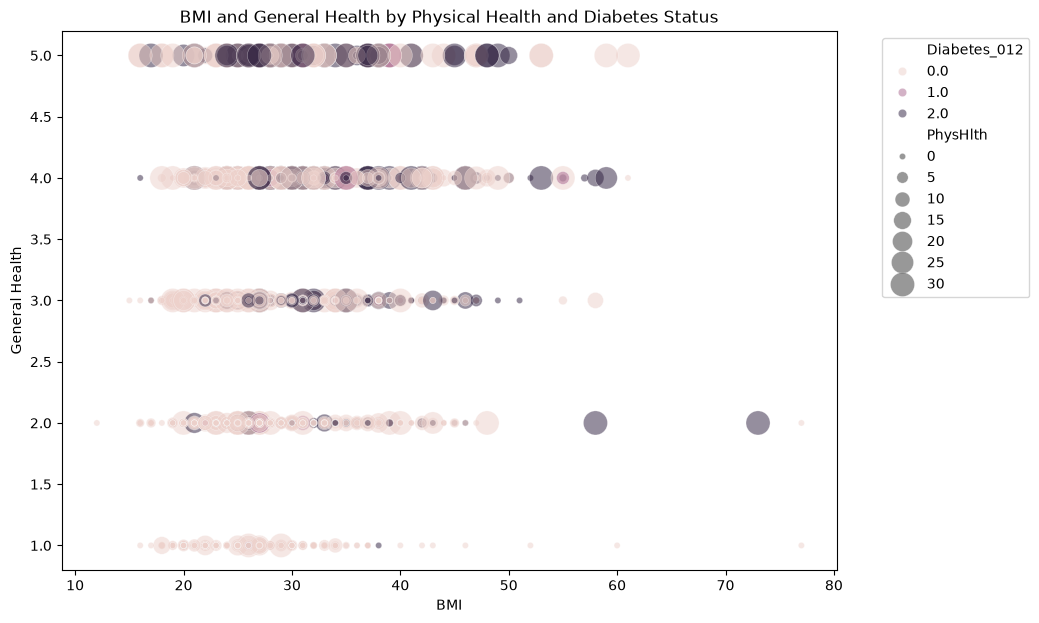

In [5]:
# Take a sample so the bubble plot is easier to read
df_sample = df.sample(n=3000, random_state=42)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_sample,
    x="BMI",
    y="GenHlth",
    size="PhysHlth",
    hue="Diabetes_012",
    sizes=(20, 300),
    alpha=0.5
)

plt.title("BMI and General Health by Physical Health and Diabetes Status")
plt.xlabel("BMI")
plt.ylabel("General Health")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")

plt.show()

The bubble plot shows that participants who reported worse general health also tended to have more physically unhealthy days, which is shown by the larger bubbles in the higher GenHlth categories. Participants with diabetes also appear more frequently among the poorer general health categories and across moderate to higher BMI values. The plot is somewhat crowded because general health is measured using only five categories, but it is still useful for showing the relationship among BMI, general health, physical health, and diabetes status at the same time

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np

# Select variables for PCA
pca_vars = [
    "BMI",
    "HighBP",
    "HighChol",
    "GenHlth",
    "PhysHlth",
    "Age",
    "Income"
]

# Create a dataframe with only the selected variables
pca_data = df[pca_vars]

# Standardize the variables so they are on the same scale
scaler = StandardScaler()
pca_scaled = scaler.fit_transform(pca_data)

# Perform PCA using all selected variables
pca = PCA(n_components=len(pca_vars))
pca.fit(pca_scaled)

# Show the amount of variance explained by each principal component
print("Explained variance ratios:")
print(pca.explained_variance_ratio_)

# Show cumulative explained variance
print("\nCumulative explained variance:")
print(np.cumsum(pca.explained_variance_ratio_))

Explained variance ratios:
[0.32599007 0.17594867 0.14171728 0.1109201  0.10065745 0.08265438
 0.06211205]

Cumulative explained variance:
[0.32599007 0.50193874 0.64365602 0.75457612 0.85523357 0.93788795
 1.        ]


In [7]:
# Put the PCA component weights into a table
components_df = pd.DataFrame(
    pca.components_,
    columns=pca_vars,
    index=[
        "PC1",
        "PC2",
        "PC3",
        "PC4",
        "PC5",
        "PC6",
        "PC7"
    ]
)

components_df

,BMI,HighBP,HighChol,GenHlth,PhysHlth,Age,Income
PC1,0.250855,0.419549,0.329113,0.508434,0.414297,0.303947,-0.360837
PC2,-0.194273,0.355167,0.445355,-0.303010,-0.390326,0.560761,0.281338
PC3,0.830189,0.210161,0.125041,-0.066057,-0.239974,-0.303650,0.311173
PC4,-0.174117,-0.240754,0.478350,0.166754,0.461470,-0.195310,0.635606
PC5,-0.035426,-0.321673,0.667451,-0.087480,-0.279394,-0.325466,-0.508074
PC6,-0.409825,0.683744,-0.002670,0.062303,-0.077046,-0.595554,0.005320
PC7,-0.102899,-0.157242,-0.058241,0.778444,-0.566979,0.046918,0.177916


The first principal component explained about 32.6% of the variance, while the first two explained about 50.2%. PC1 was mainly associated with poorer general health, high blood pressure, physical health problems, high cholesterol, older age, and lower income. This suggests that PC1 represents a general poorer-health or higher-risk profile. Overall, more than one principal component is needed to represent the dataset well.

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Model 1: Predict general health using physical health only
model1 = LinearRegression()

X1 = df[["PhysHlth"]]
y = df["GenHlth"]

model1.fit(X1, y)

pred1 = model1.predict(X1)

print("Model 1: PhysHlth only")
print("MSE:", mean_squared_error(y, pred1))
print("R²:", r2_score(y, pred1))

Model 1: PhysHlth only
MSE: 0.8277373724815841
R²: 0.2749572309909595


In [9]:
# Model 2: Add income as another predictor
model2 = LinearRegression()

X2 = df[["PhysHlth", "Income"]]

model2.fit(X2, y)

pred2 = model2.predict(X2)

print("Model 2: PhysHlth + Income")
print("MSE:", mean_squared_error(y, pred2))
print("R²:", r2_score(y, pred2))

Model 2: PhysHlth + Income
MSE: 0.7626518386446474
R²: 0.3319678206349762


In [10]:
# Model 3: Use several variables together
model3 = LinearRegression()

X3 = df[
    [
        "PhysHlth",
        "Income",
        "HighBP",
        "HighChol",
        "BMI",
        "Age"
    ]
]

model3.fit(X3, y)

pred3 = model3.predict(X3)

print("Model 3: Multiple features")
print("MSE:", mean_squared_error(y, pred3))
print("R²:", r2_score(y, pred3))

Model 3: Multiple features
MSE: 0.6963981989273802
R²: 0.3900015931750743


In [11]:
print("R² Comparison")
print("Model 1:", r2_score(y, pred1))
print("Model 2:", r2_score(y, pred2))
print("Model 3:", r2_score(y, pred3))

R² Comparison
Model 1: 0.2749572309909595
Model 2: 0.3319678206349762
Model 3: 0.3900015931750743


The linear regression results improved as more relevant features were added. Using physical health alone explained about 27.5% of the variation in general health. Adding income increased this to 33.2%, and the model using several health and demographic variables explained about 39.0%. This suggests that general health is influenced by multiple factors rather than one variable alone.

In [12]:
# Check for BMI outliers using the IQR method

Q1 = df["BMI"].quantile(0.25)
Q3 = df["BMI"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

bmi_outliers = df[
    (df["BMI"] < lower_bound) |
    (df["BMI"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of BMI outliers:", len(bmi_outliers))

bmi_outliers["BMI"].describe()

Lower bound: 13.5
Upper bound: 41.5
Number of BMI outliers: 9847


count    9847.000000
mean       48.510815
std         9.656683
min        12.000000
25%        43.000000
50%        45.000000
75%        50.000000
max        98.000000
Name: BMI, dtype: float64

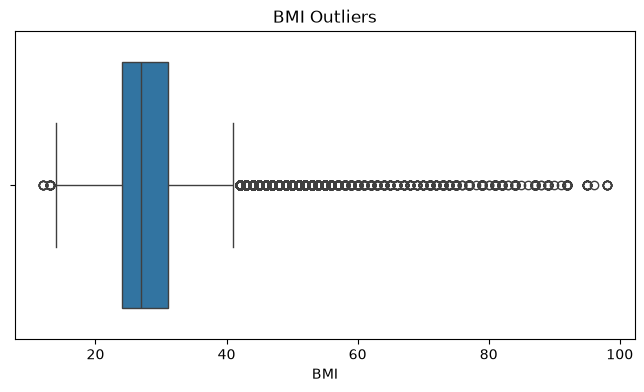

In [14]:
# to visualize the outliers 
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["BMI"])

plt.title("BMI Outliers")
plt.xlabel("BMI")

plt.show()

The data appear usable and the relationships generally match what I expected. Poorer general health, high blood pressure, higher BMI, and other health factors were associated with diabetes status. Some BMI values appear to be outliers, but they may still represent valid observations and should not automatically be removed. PCA showed that the first component explained about 32.6% of the variance and the first two explained about 50.2%, so reducing the dataset to only one or two dimensions would lose a substantial amount of information. Linear regression also showed that using several health and demographic variables together predicted general health better than using only one variable.

# 4. Storytelling With Data plot

Reproduce any graph of your choice in p. 136-150 of the Storytelling With Data book as best you can. ("The power of super-categories" to the end of chapter 5). You do not have to get the exact data values right, just the overall look and feel.

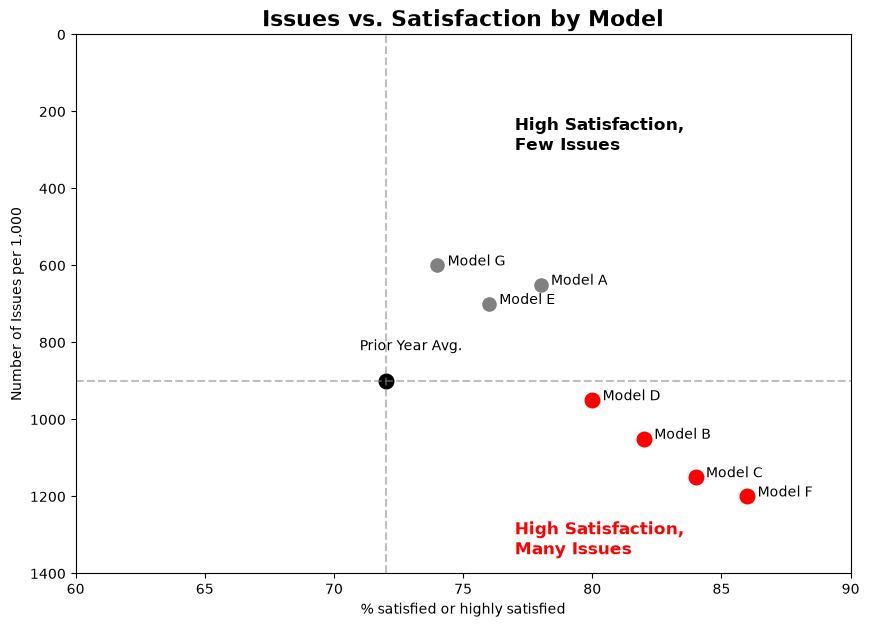

In [15]:
import matplotlib.pyplot as plt

# Approximate data to recreate Figure 5.6
models = ["Model A", "Model B", "Model C",
          "Model D", "Model E", "Model F", "Model G"]

satisfaction = [78, 82, 84, 80, 76, 86, 74]
issues = [650, 1050, 1150, 950, 700, 1200, 600]

# Prior year average
prior_satisfaction = 72
prior_issues = 900

plt.figure(figsize=(10, 7))

# Plot all models
plt.scatter(
    satisfaction,
    issues,
    s=90,
    color="gray"
)

# Highlight models with high satisfaction but many issues
for i in [1, 2, 3, 5]:
    plt.scatter(
        satisfaction[i],
        issues[i],
        s=110,
        color="red"
    )

# Add model labels
for i, model in enumerate(models):
    plt.text(
        satisfaction[i] + 0.4,
        issues[i],
        model,
        fontsize=10
    )

# Prior year average point
plt.scatter(
    prior_satisfaction,
    prior_issues,
    s=110,
    color="black"
)

plt.text(
    prior_satisfaction - 1,
    prior_issues - 80,
    "Prior Year Avg.",
    fontsize=10
)

# Reference lines
plt.axvline(
    x=prior_satisfaction,
    color="gray",
    linestyle="--",
    alpha=0.5
)

plt.axhline(
    y=prior_issues,
    color="gray",
    linestyle="--",
    alpha=0.5
)

# Super-category labels
plt.text(
    77,
    300,
    "High Satisfaction,\nFew Issues",
    fontsize=12,
    weight="bold"
)

plt.text(
    77,
    1350,
    "High Satisfaction,\nMany Issues",
    fontsize=12,
    weight="bold",
    color="red"
)

plt.title(
    "Issues vs. Satisfaction by Model",
    fontsize=16,
    weight="bold"
)

plt.xlabel("% satisfied or highly satisfied")
plt.ylabel("Number of Issues per 1,000")

plt.xlim(60, 90)
plt.ylim(1400, 0)

plt.grid(False)

plt.show()

I recreated Figure 5.6 from Storytelling With Data. The graph uses color, labels, and reference lines to create a clear visual hierarchy. The red points highlight the models with high customer satisfaction but many issues, while the gray points provide context without drawing too much attention. The quadrant labels also make the graph easier to interpret quickly.